# Week 5: Support Vector Machines

This notebook applies Support Vector Machines (SVMs) to three marketing datasets. Linear and nonlinear kernels will be evaluated to determine whether SVMs can improve classification performance compared with logistic regression. Regularization and hyperparameter optimization will also be examined using cross-validation. Training and testing performance will be compared to evaluate model generalization and potential overfitting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

sns.set_theme(style="whitegrid")

In [2]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing: (734, 19)


## Dataset 1: Digital Marketing Campaign

### Linear Support Vector Machine

A linear SVM was used to predict whether a customer would convert based on five marketing-related features. StandardScaler was applied to standardize the predictors before training the model. The results will provide a baseline for comparing different SVM kernels and regularization settings.

In [3]:
features1 = ["AdSpend", "ClickThroughRate", "WebsiteVisits", "TimeOnSite", "EmailClicks"]

X1 = df1[features1]
y1 = df1["Conversion"]

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

svm_linear1 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=1))])
svm_linear1.fit(X1_train, y1_train)

pred_linear1 = svm_linear1.predict(X1_test)
score_linear1 = svm_linear1.decision_function(X1_test)

print("Accuracy:", round(accuracy_score(y1_test, pred_linear1), 4))
print("Precision:", round(precision_score(y1_test, pred_linear1), 4))
print("Recall:", round(recall_score(y1_test, pred_linear1), 4))
print("F1 Score:", round(f1_score(y1_test, pred_linear1), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, score_linear1), 4))

Accuracy: 0.8762
Precision: 0.8762
Recall: 1.0
F1 Score: 0.934
ROC-AUC: 0.5622


Accuracy, Precision, Recall, and F1 for Linear SVM were 87.62%, 87.62%, 100%, and 0.9340 respectively. On the other hand, the ROC-AUC value was 0.5622. It can be noted that the model is predicting majority class conversion and is unable to distinguish between conversion and no-conversion classes. Even though accuracy is higher, ROC-AUC values show lower classification capabilities. As compared to logistic regression in Week 4, the Linear SVM had worse performance.

In [4]:
kernel_results1 = []

for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel, C=1))])
    model.fit(X1_train, y1_train)

    pred = model.predict(X1_test)
    scores = model.decision_function(X1_test)

    kernel_results1.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y1_test, pred),
        "F1 Score": f1_score(y1_test, pred),
        "ROC-AUC": roc_auc_score(y1_test, scores)
    })

kernel_results1 = pd.DataFrame(kernel_results1)
kernel_results1.round(4)

,Kernel,Accuracy,F1 Score,ROC-AUC
0,linear,0.8762,0.9340,0.5622
1,poly,0.8762,0.9340,0.6304
2,rbf,0.8769,0.9344,0.6010


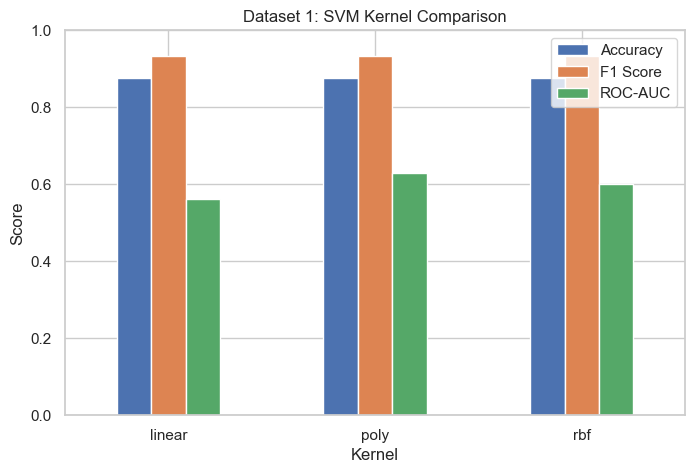

In [5]:
kernel_results1.set_index("Kernel")[["Accuracy", "F1 Score", "ROC-AUC"]].plot(kind="bar", figsize=(8, 5))

plt.ylabel("Score")
plt.title("Dataset 1: SVM Kernel Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

Three SVM kernels were evaluated: linear, polynomial, and RBF. The polynomial kernel achieved the highest ROC-AUC of 0.6304, compared with 0.5622 for linear and 0.6010 for RBF. The RBF kernel achieved the highest accuracy at 87.69%, although all three kernels produced nearly identical accuracy and F1 scores. These results suggest that nonlinear kernels may improve the model's ability to distinguish between conversions and non-conversions, but overall classification performance remains influenced by class imbalance.

### SVM Regularization

The value of C determines the trade-off between the maximization of the margin and the classification error. With low values, there is allowance for margin violation, whereas with high values, there is a focus on getting correct classifications. Different values of C were analyzed using the polynomial kernel.

In [6]:
regularization_results1 = []

for c in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="poly", C=c))])
    model.fit(X1_train, y1_train)

    train_scores = model.decision_function(X1_train)
    test_scores = model.decision_function(X1_test)

    regularization_results1.append({
        "C": c,
        "Training ROC-AUC": roc_auc_score(y1_train, train_scores),
        "Testing ROC-AUC": roc_auc_score(y1_test, test_scores)
    })

regularization_results1 = pd.DataFrame(regularization_results1)
regularization_results1.round(4)

,C,Training ROC-AUC,Testing ROC-AUC
0,0.01,0.6431,0.6322
1,0.10,0.6438,0.6348
2,1.00,0.6242,0.6304
3,10.00,0.5869,0.5677
4,100.00,0.6342,0.6278


Values of C with different levels of strictness were examined using the polynomial SVM kernel. With C = 0.1, the best testing ROC-AUC value of 0.6348 was obtained, while with C = 10, the lowest value of 0.5677 was obtained. As C increased, there was no clear improvement in the performance of the model. The training and testing ROC-AUC values showed no considerable differences for all the selected values of C, hence indicating minimal overfitting.

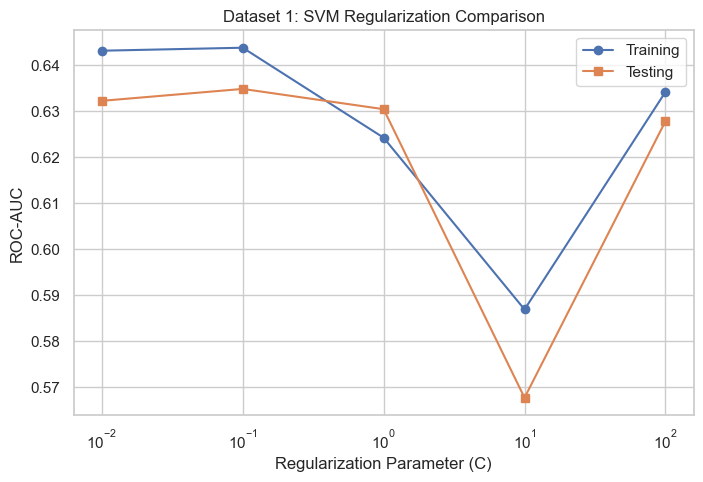

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(regularization_results1["C"], regularization_results1["Training ROC-AUC"], marker="o", label="Training")
plt.plot(regularization_results1["C"], regularization_results1["Testing ROC-AUC"], marker="s", label="Testing")
plt.xscale("log")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("ROC-AUC")
plt.title("Dataset 1: SVM Regularization Comparison")
plt.legend()
plt.show()

### Hyperparameter Optimization

GridSearchCV was used with five-fold cross-validation to optimize the SVM model. Linear, polynomial, and RBF kernels were evaluated alongside different regularization strengths and gamma settings. ROC-AUC was selected as the optimization metric because the dataset contains significantly more conversions than non-conversions. The holdout testing set was reserved for evaluating the final optimized model.

In [9]:
param_grid1 = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10]},
    {"svm__kernel": ["poly", "rbf"], "svm__C": [0.01, 0.1, 1, 10], "svm__gamma": ["scale", "auto"]}
]

grid1 = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svm", SVC())]),
    param_grid1, cv=5, scoring="roc_auc", n_jobs=-1
)

grid1.fit(X1_train, y1_train)

print("Best Parameters:", grid1.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid1.best_score_, 4))

Best Parameters: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Best Cross-Validation ROC-AUC: 0.6472


GridSearchCV selected a polynomial kernel with C = 1 and gamma = scale. The best model achieved a five-fold cross-validation ROC-AUC of 0.6472. The polynomial kernel also performed best during the initial kernel comparison. However, the cross-validation score suggests that the model's ability to distinguish between conversions and non-conversions remains modest.

In [10]:
tuned_svm1 = grid1.best_estimator_

tuned_pred1 = tuned_svm1.predict(X1_test)
tuned_score1 = tuned_svm1.decision_function(X1_test)

print("Accuracy:", round(accuracy_score(y1_test, tuned_pred1), 4))
print("Precision:", round(precision_score(y1_test, tuned_pred1), 4))
print("Recall:", round(recall_score(y1_test, tuned_pred1), 4))
print("F1 Score:", round(f1_score(y1_test, tuned_pred1), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, tuned_score1), 4))

Accuracy: 0.8762
Precision: 0.8762
Recall: 1.0
F1 Score: 0.934
ROC-AUC: 0.6304


The optimized polynomial SVM achieved 87.62% accuracy, 87.62% precision, 100% recall, and an F1 score of 0.9340. ROC-AUC increased from 0.5622 for the original Linear SVM to 0.6304. Although the polynomial kernel improved ROC-AUC, the model continued to favor the majority conversion class. Hyperparameter optimization improved ranking performance compared with the linear baseline but did not improve overall classification accuracy.

### Training vs. Testing Performance

Training and holdout testing performance were compared to evaluate whether the optimized SVM showed signs of overfitting. Accuracy, F1 score, and ROC-AUC were used to assess how well the model generalized to unseen observations.

     Metric  Training  Testing
0  Accuracy    0.8766   0.8762
1  F1 Score    0.9342   0.9340
2   ROC-AUC    0.6242   0.6304


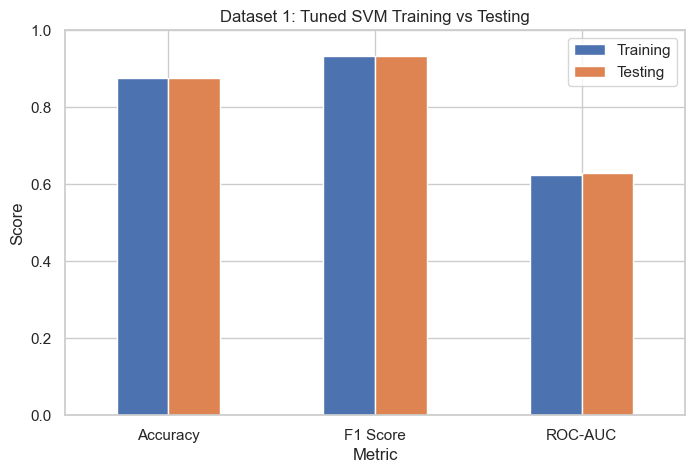

In [11]:
train_pred1 = tuned_svm1.predict(X1_train)
train_score1 = tuned_svm1.decision_function(X1_train)

performance1 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [accuracy_score(y1_train, train_pred1), f1_score(y1_train, train_pred1), roc_auc_score(y1_train, train_score1)],
    "Testing": [accuracy_score(y1_test, tuned_pred1), f1_score(y1_test, tuned_pred1), roc_auc_score(y1_test, tuned_score1)]
})

print(performance1.round(4))

performance1.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Score")
plt.title("Dataset 1: Tuned SVM Training vs Testing")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

The optimized polynomial SVM produced similar training and testing results. Training accuracy was 87.66%, compared with 87.62% on the testing set. F1 scores were also nearly identical at 0.9342 and 0.9340. ROC-AUC increased slightly from 0.6242 during training to 0.6304 during testing. These results suggest little evidence of overfitting. However, the model's classification performance remains limited by its tendency to predict the majority conversion class.

### Dataset 1 Conclusion

The Support Vector Machines were tested using linear, polynomial, and RBF kernels for predicting customer conversions. Among them, the polynomial kernel obtained the highest ROC-AUC score of 0.6304 whereas the RBF kernel had the highest accuracy rate of 87.69%. The effect of regularization tuning was done by varying C and found that there was an influence on the model’s performance but large C values didn’t necessarily improve the performance. The GridSearchCV technique obtained the best model having a polynomial kernel with C=1 and gamma=scale giving a cross validation ROC-AUC of 0.6472. There wasn’t much difference between training and testing performance indicating no evidence of overfitting. Still, the optimized model kept predicting the dominant conversion class making it useless for finding non-conversion cases. Overall, nonlinear kernels provided a higher ROC-AUC score than Linear SVM but still the performance for classification was poor. In Week 4 logistic regression model gave a ROC-AUC of 0.7044.

## Dataset 2: Marketing and Product Performance

### Linear Support Vector Machine

The linear SVM was employed in classifying marketing campaigns into those that have a high ROI or those that have a low ROI. For the target variable, the median ROI was taken into consideration. The predictors that were employed were the same as those used in previous weeks.

In [12]:
df2["High_ROI"] = (df2["ROI"] > df2["ROI"].median()).astype(int)

features2 = ["Budget", "Clicks", "Conversions", "Units_Sold", "Bundle_Price"]
X2 = df2[features2]
y2 = df2["High_ROI"]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

svm_linear2 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=1))])
svm_linear2.fit(X2_train, y2_train)

pred_linear2 = svm_linear2.predict(X2_test)
score_linear2 = svm_linear2.decision_function(X2_test)

print("Accuracy:", round(accuracy_score(y2_test, pred_linear2), 4))
print("Precision:", round(precision_score(y2_test, pred_linear2, zero_division=0), 4))
print("Recall:", round(recall_score(y2_test, pred_linear2), 4))
print("F1 Score:", round(f1_score(y2_test, pred_linear2), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, score_linear2), 4))

Accuracy: 0.51
Precision: 0.5104
Recall: 0.491
F1 Score: 0.5005
ROC-AUC: 0.503


The Linear SVM achieved 51.00% accuracy, 51.04% precision, 49.10% recall, and an F1 score of 0.5005. ROC-AUC was 0.5030. These results indicate that the model performed close to chance level when predicting high- and low-ROI campaigns. Although accuracy was slightly higher than the Week 4 logistic regression model, the selected predictors still demonstrated limited classification ability.

### SVM Kernel Comparison

Linear, polynomial, and RBF kernels were compared to determine whether nonlinear decision boundaries could improve the classification of high- and low-ROI campaigns. Accuracy, F1 score, and ROC-AUC were used to evaluate each kernel.

In [13]:
kernel_results2 = []

for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel, C=1))])
    model.fit(X2_train, y2_train)

    pred = model.predict(X2_test)
    scores = model.decision_function(X2_test)

    kernel_results2.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y2_test, pred),
        "F1 Score": f1_score(y2_test, pred),
        "ROC-AUC": roc_auc_score(y2_test, scores)
    })

kernel_results2 = pd.DataFrame(kernel_results2)
kernel_results2.round(4)

,Kernel,Accuracy,F1 Score,ROC-AUC
0,linear,0.5100,0.5005,0.5030
1,poly,0.5010,0.5030,0.5016
2,rbf,0.5115,0.5246,0.5003


Three SVM kernels were evaluated: linear, polynomial, and RBF. The RBF kernel achieved the highest accuracy of 51.15% and F1 score of 0.5246, while the linear kernel produced the highest ROC-AUC of 0.5030. All three kernels performed close to chance level, suggesting that nonlinear decision boundaries did not meaningfully improve classification performance. The selected predictors continued to show limited ability to distinguish high-ROI campaigns from low-ROI campaigns.

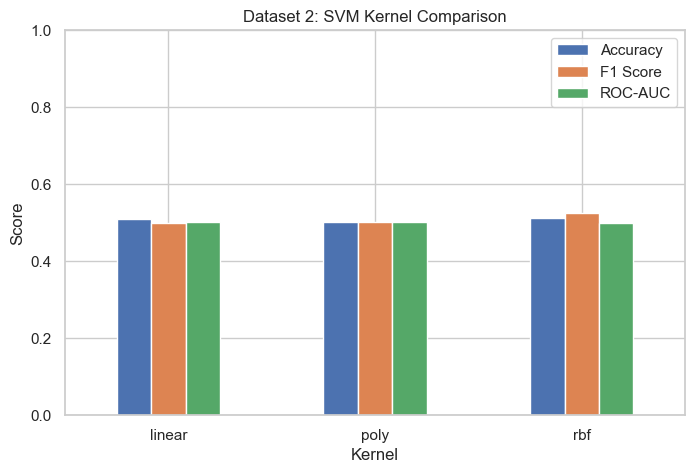

In [14]:
kernel_results2.set_index("Kernel")[["Accuracy", "F1 Score", "ROC-AUC"]].plot(kind="bar", figsize=(8, 5))

plt.ylabel("Score")
plt.title("Dataset 2: SVM Kernel Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### SVM Regularization

C was varied in different values to analyze the effect of varying it on the accuracy of the model using the linear SVM kernel. A smaller value for C leads to more margin violations, and a higher value for C increases the penalty imposed on misclassification. Comparisons of training and testing ROC-AUC scores were done to observe overfitting.

In [15]:
regularization_results2 = []

for c in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=c))])
    model.fit(X2_train, y2_train)

    train_scores = model.decision_function(X2_train)
    test_scores = model.decision_function(X2_test)

    regularization_results2.append({
        "C": c,
        "Training ROC-AUC": roc_auc_score(y2_train, train_scores),
        "Testing ROC-AUC": roc_auc_score(y2_test, test_scores)
    })

regularization_results2 = pd.DataFrame(regularization_results2)
regularization_results2.round(4)

,C,Training ROC-AUC,Testing ROC-AUC
0,0.01,0.5198,0.5029
1,0.10,0.5197,0.5030
2,1.00,0.5197,0.5030
3,10.00,0.5197,0.5030
4,100.00,0.5197,0.5030


Different values of C were evaluated using the linear SVM kernel. Training ROC-AUC remained approximately 0.52, while testing ROC-AUC stayed around 0.50 across all five values. Increasing C did not meaningfully improve model performance. The relatively small differences between training and testing suggest limited evidence of overfitting. However, the results indicate that the selected predictors provide little ability to distinguish high-ROI campaigns from low-ROI campaigns.

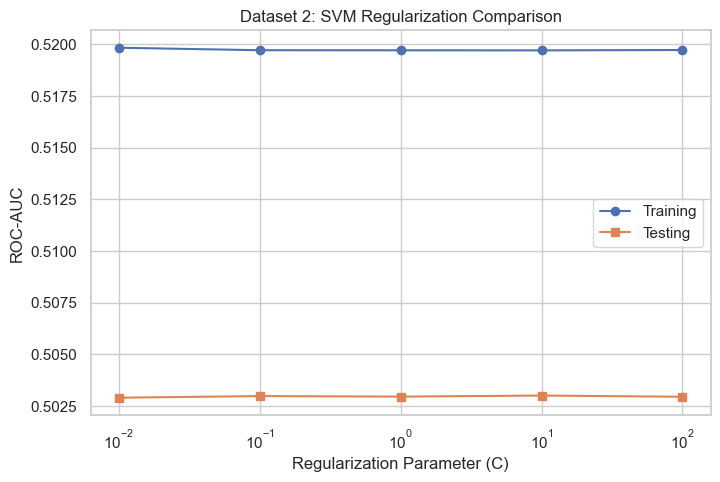

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(regularization_results2["C"], regularization_results2["Training ROC-AUC"], marker="o", label="Training")
plt.plot(regularization_results2["C"], regularization_results2["Testing ROC-AUC"], marker="s", label="Testing")
plt.xscale("log")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("ROC-AUC")
plt.title("Dataset 2: SVM Regularization Comparison")
plt.legend()
plt.show()

GridSearchCV was used with five-fold cross-validation to optimize the SVM model. Linear, polynomial, and RBF kernels were evaluated alongside different regularization strengths and gamma settings. ROC-AUC was selected as the optimization metric to measure the model's ability to distinguish high-ROI campaigns from low-ROI campaigns. The holdout testing set was reserved for evaluating the final optimized model.

In [18]:
param_grid2 = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10]},
    {"svm__kernel": ["poly", "rbf"], "svm__C": [0.01, 0.1, 1, 10], "svm__gamma": ["scale", "auto"]}
]

grid2 = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("svm", SVC())]),param_grid2, cv=5, scoring="roc_auc", n_jobs=-1)
grid2.fit(X2_train, y2_train)

print("Best Parameters:", grid2.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid2.best_score_, 4))

Best Parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best Cross-Validation ROC-AUC: 0.5128


Optimal values for the parameters obtained from the GridSearchCV are RBF kernel, C = 0.1, and gamma = scale. The optimal model yielded an ROC-AUC score of 0.5128 on the five-fold cross-validation test. Despite the flexibility of the RBF kernel in handling non-linear relations, the cross-validation score is close to the random guess score.

In [ ]:
tuned_svm2 = grid2.best_estimator_
tuned_pred2 = tuned_svm2.predict(X2_test)
tuned_score2 = tuned_svm2.decision_function(X2_test)

print("Accuracy:", round(accuracy_score(y2_test, tuned_pred2), 4))
print("Precision:", round(precision_score(y2_test, tuned_pred2, zero_division=0), 4))
print("Recall:", round(recall_score(y2_test, tuned_pred2), 4))
print("F1 Score:", round(f1_score(y2_test, tuned_pred2), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, tuned_score2), 4))

Accuracy: 0.5095
Precision: 0.508
Recall: 0.605
F1 Score: 0.5523
ROC-AUC: 0.5014


The optimized RBF SVM achieved 50.95% accuracy, 50.80% precision, 60.50% recall, and an F1 score of 0.5523. ROC-AUC was 0.5014. Compared with the original Linear SVM, the tuned model improved recall and F1 score but produced slightly lower accuracy, precision, and ROC-AUC. Overall, hyperparameter optimization changed the model's classification behavior without meaningfully improving its ability to distinguish between high- and low-ROI campaigns.

### Training vs. Testing Performance

Training and holdout testing performance were compared to evaluate potential overfitting in the optimized RBF SVM. Accuracy, F1 score, and ROC-AUC were used to assess whether the model generalized effectively to unseen observations.

     Metric  Training  Testing
0  Accuracy    0.5294   0.5095
1  F1 Score    0.5754   0.5523
2   ROC-AUC    0.5424   0.5014


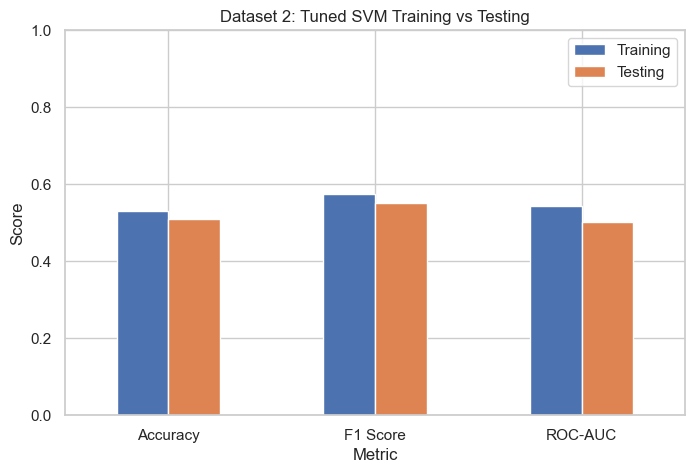

In [20]:
train_pred2 = tuned_svm2.predict(X2_train)
train_score2 = tuned_svm2.decision_function(X2_train)

performance2 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [accuracy_score(y2_train, train_pred2), f1_score(y2_train, train_pred2), roc_auc_score(y2_train, train_score2)],
    "Testing": [accuracy_score(y2_test, tuned_pred2), f1_score(y2_test, tuned_pred2), roc_auc_score(y2_test, tuned_score2)]
})

print(performance2.round(4))

performance2.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Score")
plt.title("Dataset 2: Tuned SVM Training vs Testing")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

The optimized SVM using RBF kernel demonstrated a classification accuracy of 50.95%, precision of 50.80%, recall of 60.50%, and F1-score of 0.5523. The ROC-AUC value was 0.5014. The optimized model compared to the initial Linear SVM model has performed better in terms of recall and F1 score, but worse concerning accuracy, precision, and ROC-AUC.

### Dataset 2 Conclusion

Support Vector Machines were evaluated using linear, polynomial, and RBF kernels to classify high- and low-ROI campaigns. The RBF kernel achieved the highest initial accuracy of 51.15%, while the linear kernel produced the highest ROC-AUC of 0.5030. Changing the regularization parameter C had almost no effect on the linear model's performance. GridSearchCV selected an RBF kernel with C = 0.1 and gamma = scale, achieving a cross-validation ROC-AUC of 0.5128. The tuned model improved recall and F1 score compared with the original Linear SVM, but testing ROC-AUC remained close to 0.50. Training performance was slightly higher than testing performance, suggesting some overfitting. Overall, neither nonlinear kernels nor hyperparameter optimization meaningfully improved the model's ability to distinguish high-ROI campaigns from low-ROI campaigns.

## Dataset 3: Synthetic B2B CRM & Marketing Dataset

### Linear Support Vector Machine

A Linear SVM was used to classify companies based on whether their contracts were Active or Not Active. The same predictors from previous weeks were used for consistency, and feature scaling was applied before training the model.

In [21]:
df3["Active_Contract"] = (df3["Contract_Status"] == "Active").astype(int)

features3 = ["Annual_Revenue (M₺)", "Marketing_Spend (K₺)", "Days_Since_Last_Purchase", "Total_Purchases_Last_Year"]
X3 = df3[features3]
y3 = df3["Active_Contract"]

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

svm_linear3 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=1))])
svm_linear3.fit(X3_train, y3_train)

pred_linear3 = svm_linear3.predict(X3_test)
score_linear3 = svm_linear3.decision_function(X3_test)

print("Accuracy:", round(accuracy_score(y3_test, pred_linear3), 4))
print("Precision:", round(precision_score(y3_test, pred_linear3, zero_division=0), 4))
print("Recall:", round(recall_score(y3_test, pred_linear3), 4))
print("F1 Score:", round(f1_score(y3_test, pred_linear3), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, score_linear3), 4))

Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379
ROC-AUC: 0.4676


The Linear SVM gave an accuracy, precision, and recall rate of 72.11%, 72.11%, and 100% respectively, as well as an F1 score of 0.8379. Nonetheless, ROC-AUC was 0.4676. From the results above, it is clear that the classifier does not differentiate the two classes effectively; instead, the classifier predicts more Active contracts since this is the dominant class. While the accuracy looks reasonable, the ROC-AUC is poor. It is better compared to Week 4 logistic regression classifier.

### SVM Kernel Comparison

Linear, polynomial, and RBF kernels were compared to determine whether nonlinear decision boundaries could improve the classification of Active and Not Active contracts. Accuracy, F1 score, and ROC-AUC were used to evaluate each kernel.

In [22]:
kernel_results3 = []

for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel, C=1))])
    model.fit(X3_train, y3_train)

    pred = model.predict(X3_test)
    scores = model.decision_function(X3_test)

    kernel_results3.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y3_test, pred),
        "F1 Score": f1_score(y3_test, pred),
        "ROC-AUC": roc_auc_score(y3_test, scores)
    })

kernel_results3 = pd.DataFrame(kernel_results3)
kernel_results3.round(4)

,Kernel,Accuracy,F1 Score,ROC-AUC
0,linear,0.7211,0.8379,0.4676
1,poly,0.7211,0.8379,0.4542
2,rbf,0.7211,0.8379,0.4878


Three SVM kernels were evaluated: linear, polynomial, and RBF. All three achieved identical accuracy of 72.11% and an F1 score of 0.8379. The RBF kernel produced the highest ROC-AUC of 0.4878, compared with 0.4676 for linear and 0.4542 for polynomial. However, all three scores remained below 0.50, indicating weak classification performance. These results suggest that nonlinear kernels did not meaningfully improve the model's ability to distinguish Active from Not Active contracts.

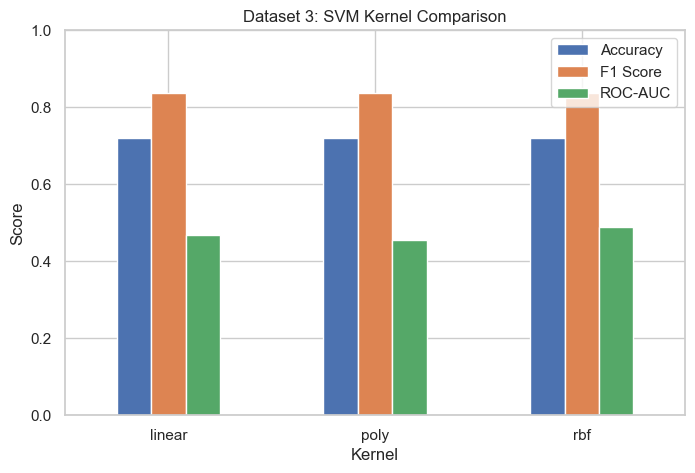

In [23]:
kernel_results3.set_index("Kernel")[["Accuracy", "F1 Score", "ROC-AUC"]].plot(kind="bar", figsize=(8, 5))

plt.ylabel("Score")
plt.title("Dataset 3: SVM Kernel Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### SVM Regularization

Different values of the regularization parameter C were evaluated using the RBF kernel. Smaller values of C allow more margin violations, while larger values penalize classification errors more heavily. Training and testing ROC-AUC scores were compared to examine the effect of regularization and identify potential overfitting.

In [24]:
regularization_results3 = []

for c in [0.01, 0.1, 1, 10, 100]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", C=c))])
    model.fit(X3_train, y3_train)

    train_scores = model.decision_function(X3_train)
    test_scores = model.decision_function(X3_test)

    regularization_results3.append({
        "C": c,
        "Training ROC-AUC": roc_auc_score(y3_train, train_scores),
        "Testing ROC-AUC": roc_auc_score(y3_test, test_scores)
    })

regularization_results3 = pd.DataFrame(regularization_results3)
regularization_results3.round(4)

,C,Training ROC-AUC,Testing ROC-AUC
0,0.01,0.6136,0.4694
1,0.10,0.6658,0.4883
2,1.00,0.6955,0.4878
3,10.00,0.7136,0.5120
4,100.00,0.7407,0.4890


C values were analyzed by applying the RBF SVM kernel. The training ROC-AUC value increased from 0.6136 when C was 0.01 to 0.7407 when C was equal to 100. Yet, the testing ROC-AUC value stayed at almost 0.50 irrespective of the setting for C value. C was set to 10 to get the maximum testing ROC-AUC which was equal to 0.5120 while C was set to 100 to get the maximum training ROC-AUC of 0.7407 but lower testing ROC-AUC of 0.4890.

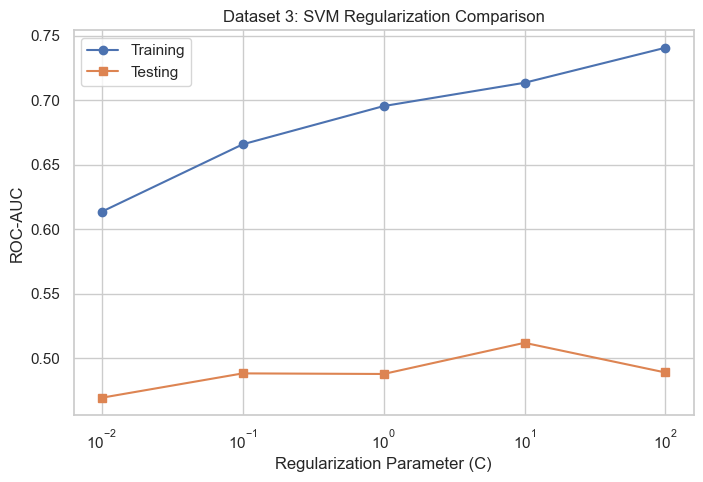

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(regularization_results3["C"], regularization_results3["Training ROC-AUC"], marker="o", label="Training")
plt.plot(regularization_results3["C"], regularization_results3["Testing ROC-AUC"], marker="s", label="Testing")

plt.xscale("log")
plt.xlabel("Regularization Parameter (C)")
plt.ylabel("ROC-AUC")
plt.title("Dataset 3: SVM Regularization Comparison")
plt.legend()
plt.show()

### Hyperparameter Optimization

GridSearchCV was used with five fold cross validation for tuning the parameters for the SVM classifier. Linear, Polynomial, and RBF kernels along with regularization and gamma parameters were tried out. ROC-AUC was used for comparing models since the data had more cases of Active than Not Active.

In [26]:
param_grid3 = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10]},
    {"svm__kernel": ["poly", "rbf"], "svm__C": [0.01, 0.1, 1, 10], "svm__gamma": ["scale", "auto"]}
]

grid3 = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svm", SVC())]),
    param_grid3, cv=5, scoring="roc_auc", n_jobs=-1
)

grid3.fit(X3_train, y3_train)

print("Best Parameters:", grid3.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid3.best_score_, 4))

Best Parameters: {'svm__C': 0.01, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best Cross-Validation ROC-AUC: 0.5379


The RBF kernel with the C parameter value of 0.01 and gamma value of scale was found to be the best by GridSearchCV. The model gave an ROC-AUC score of 0.5379 during the cross-validation process, which is a sign of poor classification ability.

In [27]:
best_svm3 = grid3.best_estimator_
pred_tuned3 = best_svm3.predict(X3_test)
score_tuned3 = best_svm3.decision_function(X3_test)

print("Accuracy:", round(accuracy_score(y3_test, pred_tuned3), 4))
print("Precision:", round(precision_score(y3_test, pred_tuned3), 4))
print("Recall:", round(recall_score(y3_test, pred_tuned3), 4))
print("F1 Score:", round(f1_score(y3_test, pred_tuned3), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, score_tuned3), 4))

Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379
ROC-AUC: 0.4694


However, the accuracy, precision, recall, F1 score, and ROC-AUC values of the optimal RBF SVM model were 0.7211, 0.7211, 1.0000, 0.8379, and 0.4694 respectively which are almost similar to those of the original linear SVM model. Though the accuracy is quite high, but the problem is that it predicts every observation to be of Active class.

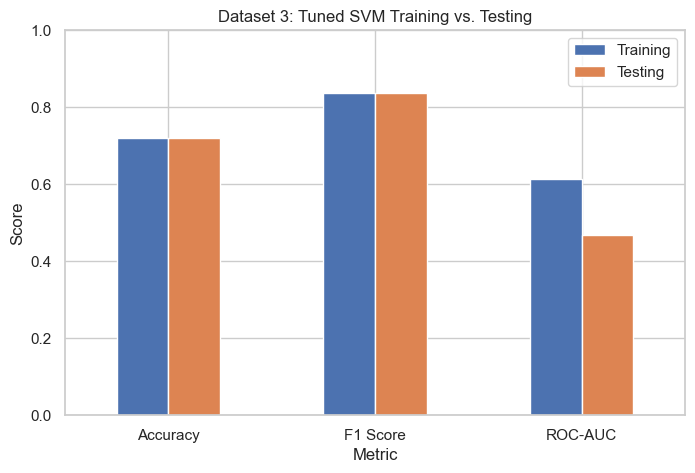

,Metric,Training,Testing
0,Accuracy,0.7189,0.7211
1,F1 Score,0.8365,0.8379
2,ROC-AUC,0.6136,0.4694


In [28]:
train_pred3 = best_svm3.predict(X3_train)
train_score3 = best_svm3.decision_function(X3_train)

comparison3 = pd.DataFrame({
    "Metric": ["Accuracy", "F1 Score", "ROC-AUC"],
    "Training": [
        accuracy_score(y3_train, train_pred3),
        f1_score(y3_train, train_pred3),
        roc_auc_score(y3_train, train_score3)
    ],
    "Testing": [
        accuracy_score(y3_test, pred_tuned3),
        f1_score(y3_test, pred_tuned3),
        roc_auc_score(y3_test, score_tuned3)
    ]
})

comparison3.set_index("Metric").plot(kind="bar", figsize=(8, 5))
plt.title("Dataset 3: Tuned SVM Training vs. Testing")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

comparison3.round(4)

The optimized SVM model had similar performance in both training and testing phases, where their accuracy measures were 0.7189 and 0.7211 respectively. Their F1 score measures were also almost the same, being 0.8365 and 0.8379 for training and testing respectively. On the other hand, the measure of ROC-AUC fell from 0.6136 in training to 0.4694 in testing phase. This implies that the model faced difficulties in generalizing its discrimination capabilities.

### Dataset 3 Conclusion

The SVM models demonstrated limited effectiveness in predicting contract status. While the models reached about 72% accuracy, they predicted the dominant class and not whether the contract was Active or Not Active. Comparing linear, polynomial, and RBF kernels showed minimal improvement. Increasing the regularization parameter also improved training performance without consistently improving testing performance. Hyperparameter optimization selected an RBF kernel with C = 0.01 and gamma = scale, but the final model achieved a testing ROC-AUC of only 0.4694. Overall, these findings suggest that the selected features provide limited predictive information for contract status, and additional features or alternative modeling approaches may be necessary.

## Conclusion

In Week 5, Support Vector Machine (SVM) models were applied to three datasets to evaluate classification performance and examine how different kernels and regularization settings affect results. Feature scaling was used for each dataset, and linear, polynomial, and RBF kernels were compared. Hyperparameter tuning was also performed using GridSearchCV. Dataset 1 produced the strongest results, achieving 87.62% accuracy and a ROC-AUC of 0.6304, although the model still struggled to distinguish between classes. Dataset 2 showed the weakest overall performance, with accuracy near 51% and ROC-AUC close to 0.50. Dataset 3 achieved 72.11% accuracy, but this was largely due to predicting the majority class rather than effectively identifying contract status. Overall, changing kernels and adjusting regularization improved some training results but did not consistently improve testing performance. These findings demonstrate the importance of evaluating models beyond accuracy, especially when datasets contain imbalanced classes. While SVMs offer flexibility through different kernels and regularization settings, their effectiveness ultimately depends on the predictive information available in the dataset.